# Iris Flower Classification

## Objective
To build machine learning models that classify Iris flowers into three species.

## Dataset
The built-in Iris dataset from Scikit-learn.

## Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn.

## Workflow
1. Data loading and inspection
2. Exploratory Data Analysis (EDA)
3. Feature selection
4. Model training
5. Model evaluation and comparison
6. Conclusion

In [107]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")


In [108]:
iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["species"] = iris.target

df["species_name"] = df["species"].map(
    dict(enumerate(iris.target_names))
)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [109]:
print("Dataset shape:", df.shape)

Dataset shape: (150, 6)


In [110]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
 5   species_name       150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [111]:
print(df.isnull().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
species_name         0
dtype: int64


In [112]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


## Exploratory Data Analysis (EDA)

### Species Distribution

We will examine how many samples belong to each Iris species.

In [113]:
print(df["species_name"].value_counts())

species_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


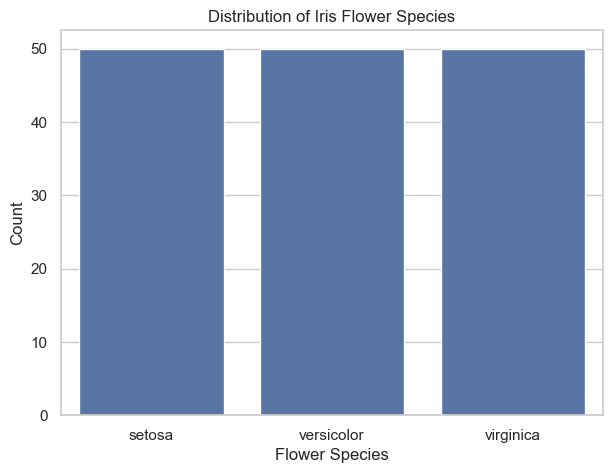

In [114]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="species_name")

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Flower Species")
plt.ylabel("Count")

plt.savefig("images/01_species_distribution.png",
            dpi=300, bbox_inches="tight")

plt.show()

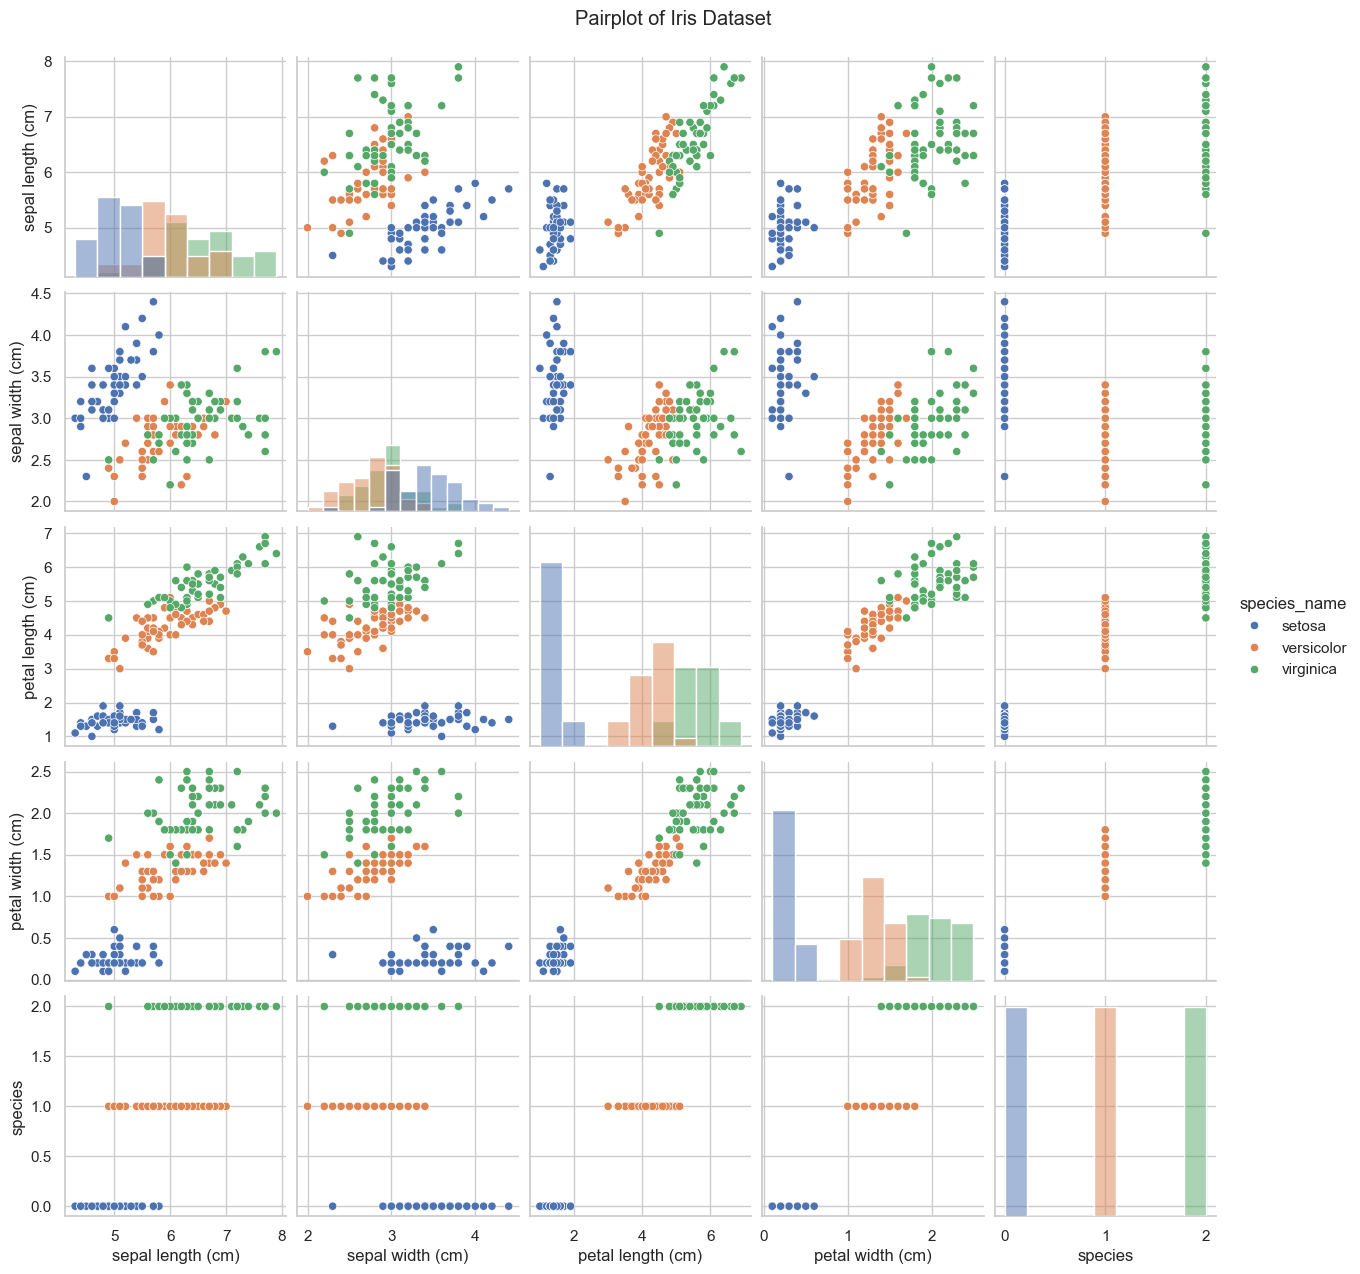

In [133]:
g = sns.pairplot(
    df,
    hue="species_name",
    diag_kind="hist"
)

g.fig.suptitle("Pairplot of Iris Dataset", y=1.02)

g.savefig(
    "images/02_iris_pairplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

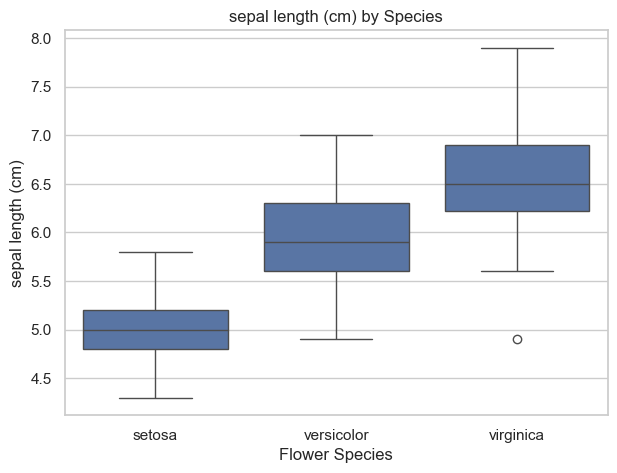

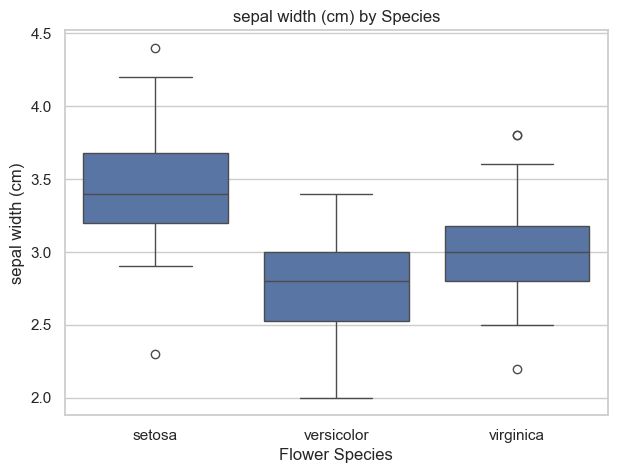

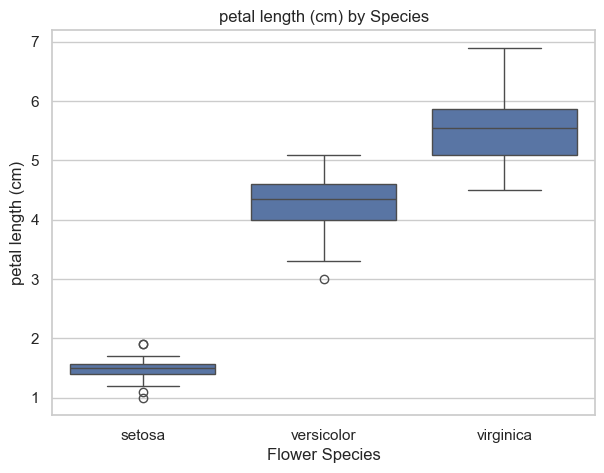

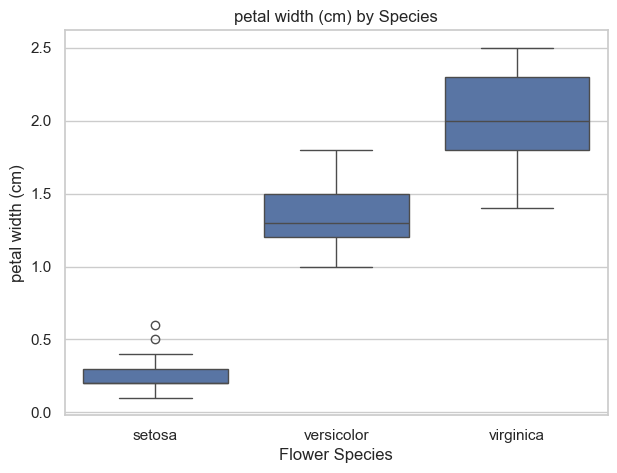

In [116]:
features = iris.feature_names

for feature in features:
    plt.figure(figsize=(7, 5))

    sns.boxplot(data=df, x="species_name", y=feature)

    plt.title(f"{feature} by Species")
    plt.xlabel("Flower Species")
    plt.ylabel(feature)

    filename = feature.replace(" ", "_").replace("(", "").replace(")", "")

    plt.savefig(f"images/03_boxplot_{filename}.png",
                dpi=300, bbox_inches="tight")

    plt.show()
    

## Feature Selection

The four numerical flower measurements are selected as input features.
The species column is selected as the target variable.

All four features are retained because each may contribute useful
information to the classification task.

In [117]:
X = df[iris.feature_names]
y = df["species"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (150, 4)
Target shape: (150,)


In [118]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (120, 4)
Testing features: (30, 4)
Training target: (120,)
Testing target: (30,)


In [119]:
print("Training distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting distribution:")
print(y_test.value_counts().sort_index())

Training distribution:
species
0    40
1    40
2    40
Name: count, dtype: int64

Testing distribution:
species
0    10
1    10
2    10
Name: count, dtype: int64


## Model Building and Training

We will train two classification algorithms:
1. Logistic Regression
2. K-Nearest Neighbors (KNN)

Feature scaling is applied using StandardScaler.

In [120]:
# Create Logistic Regression model
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

# Create KNN model
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

print("Both models created successfully!")

Both models created successfully!


In [121]:
# Train Logistic Regression
logistic_model.fit(X_train, y_train)

# Train KNN
knn_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [122]:
# Predictions using Logistic Regression
y_pred_lr = logistic_model.predict(X_test)

# Predictions using KNN
y_pred_knn = knn_model.predict(X_test)

print("Logistic Regression Predictions:")
print(y_pred_lr)

print("\nKNN Predictions:")
print(y_pred_knn)

Logistic Regression Predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]

KNN Predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 1 1 0 2 0]


## Model Evaluation

We evaluate both classification models using accuracy,
confusion matrices, and classification reports.

In [123]:
# Calculate accuracy
accuracy_lr = accuracy_score(y_test, y_pred_lr)
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("Logistic Regression Accuracy:", accuracy_lr)
print("KNN Accuracy:", accuracy_knn)

Logistic Regression Accuracy: 0.9333333333333333
KNN Accuracy: 0.9333333333333333


In [124]:
print("Logistic Regression:", accuracy_lr * 100, "%")
print("KNN:", accuracy_knn * 100, "%")

Logistic Regression: 93.33333333333333 %
KNN: 93.33333333333333 %


<Figure size 600x500 with 0 Axes>

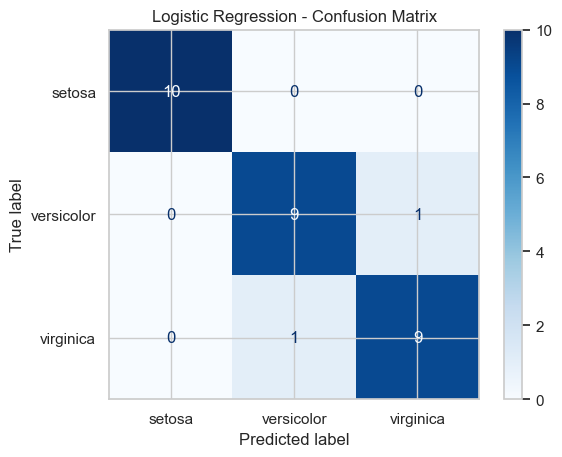

In [125]:
# Logistic Regression Confusion Matrix
plt.figure(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    display_labels=iris.target_names,
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")

plt.savefig("images/04_logistic_confusion_matrix.png",
            dpi=300, bbox_inches="tight")

plt.show()

<Figure size 600x500 with 0 Axes>

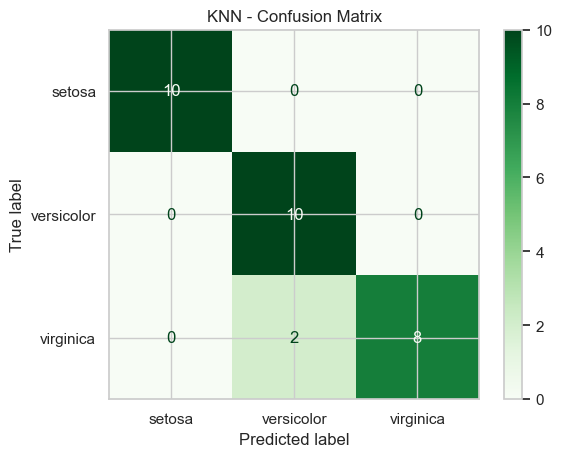

In [126]:
# KNN Confusion Matrix
plt.figure(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn,
    display_labels=iris.target_names,
    cmap="Greens"
)

plt.title("KNN - Confusion Matrix")

plt.savefig("images/05_knn_confusion_matrix.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [127]:
print("Logistic Regression Classification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=iris.target_names
))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [128]:
print("KNN Classification Report:")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=iris.target_names
))

KNN Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



In [129]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN"],
    "Accuracy": [accuracy_lr, accuracy_knn],
    "Macro Precision": [0.93, 0.94],
    "Macro Recall": [0.93, 0.93],
    "Macro F1-Score": [0.93, 0.93]
})

comparison

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Logistic Regression,0.933333,0.93,0.93,0.93
1,KNN,0.933333,0.94,0.93,0.93


## Best Model Selection

Both Logistic Regression and KNN achieved 93.33% accuracy.

Logistic Regression is selected as the preferred model because
it provides more balanced precision and recall across the
three Iris species.

KNN also performed well, but its recall for Virginica was
lower than Logistic Regression.

Therefore, Logistic Regression is selected as the final model.

In [130]:
best_model = logistic_model

print("Selected Model: Logistic Regression")
print("Test Accuracy:", accuracy_score(y_test, best_model.predict(X_test)))

Selected Model: Logistic Regression
Test Accuracy: 0.9333333333333333


In [131]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

prediction = best_model.predict(new_flower)

predicted_species = iris.target_names[prediction[0]]

print("Predicted Flower Species:", predicted_species)

Predicted Flower Species: setosa


## Conclusion

In this project, I developed a machine learning model to classify Iris flowers into three species: Setosa, Versicolor, and Virginica.

I performed Exploratory Data Analysis (EDA), checked missing values, visualized feature distributions, and divided the dataset into training and testing sets using an 80:20 ratio.

I trained and evaluated two classification algorithms: Logistic Regression and K-Nearest Neighbors (KNN).

Both models achieved **93.33% accuracy** on the test dataset. Logistic Regression was selected as the preferred model because it provided more balanced class-wise performance.

Finally, I tested the selected model with a new flower sample, and it successfully predicted the species as Setosa.

This project helped me understand the basic machine learning workflow, data visualization, model training, and model evaluation.